# 20 - Petrophys for LLM agents (MCP)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/20_mcp_server.ipynb)

**Part B - Petrophys Curriculum**

LLM applications such as Claude Desktop, Claude Code, Cursor and VS Code can call
tools through the **Model Context Protocol (MCP)**. Petrophys ships an MCP server, so a
model can load wells, run the interpretation, read the trace, summarize zones, plot
logs and export results - using exactly the validated workflow you have learned in
this course, never a re-implementation of the physics.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml,mcp]"

## Learning goals

- Start the Petrophys MCP server and see the tools a model is offered.
- Follow a complete agent session: load, interpret, explain, summarize, plot, export.
- See how the server keeps the model honest: validated settings, actionable errors,
  skip reasons and data-quality warnings in every answer.
- Connect a real MCP client to your own well folders.

## Why this matters

A language model is good at planning an analysis and explaining it, but it must not
invent petrophysics. With MCP the model *calls* Petrophys: every number it reports comes
from the same traced workflow as `pp.interpret`, every skipped step has a stated
reason, and every setting it passes is validated before anything runs. The server also
limits file access to folders you choose.

### Prerequisites

The MCP extra needs Python 3.10+: `pip install "petrophys[mcp]"`. Real clients start
the server as a separate process (`petrophys-mcp`); in this notebook we connect to it
in-process with the MCP Python client, which sends exactly the same requests.

## 1 - Start the server and list its tools

`create_server` builds the server; `roots` are the folders the model may read and
write. The server keeps loaded wells and results, and clients can connect and
disconnect. Each tool comes with a one-line description for the model:

In [2]:
from base64 import b64decode

import pandas as pd
from IPython.display import Image
from mcp import Client

from petrophys.mcp import create_server

server = create_server(roots=["."])
async with Client(server) as client:
    tools = (await client.list_tools()).tools
{tool.name: tool.description.splitlines()[0] for tool in tools}

{'list_sample_wells': 'List the bundled sample wells by collection, with what each is good for.',
 'interpretation_settings': 'Look up interpret_well settings (name, default, unit, accepted values).',
 'load_well': 'Load a well file and summarize it.',
 'load_sample_well': 'Load a bundled sample well; returns the same summary as load_well.',
 'list_loaded': 'List the wells and interpretation runs held in this session, with their ids.',
 'describe_well': 'Summarize a loaded well again (same content as load_well) without reloading it.',
 'check_data_quality': 'Data-quality report with a recommended fix for every problem.',
 'curve_statistics': 'Statistics of curves over a depth window: valid count, min, P10, median, mean, P90, max.',
 'curve_values': 'Curve values versus depth, decimated, for inspecting a short interval.',
 'interpret_well': 'Run the full interpretation (petrophys.interpret) on a well and summarize it.',
 'interpret_wells': 'Interpret several wells with the same settings

Each tool also carries a JSON schema whose parameters are described for the model.
Below are the parameters of `load_well`, with their types and descriptions:

In [3]:
next(tool for tool in tools if tool.name == "load_well").input_schema["properties"]

{'path': {'description': "LAS, DLIS, CSV or TSV file inside the allowed folders; relative paths start in the server's folder (e.g. 'my_well.las').",
  'type': 'string'},
 'depth_unit': {'description': 'Depth unit; required for CSV/TSV files.',
  'enum': ['m', 'ft'],
  'type': 'string'},
 'formations': {'description': 'Formation tops/intervals file (CSV/Excel) to attach; enables per-formation summaries and tops on plots.',
  'type': 'string'},
 'lithology': {'description': 'Lithology intervals file (top, bottom, lithology) to attach.',
  'type': 'string'},
 'well_id': {'description': 'Id to store the well under; defaults to the well name. An id already used by another file is refused.',
  'type': 'string'}}

A small helper calls one tool the way a client does and returns its result: the JSON
answer in `structured_content`, or the error text in `content` when `is_error` is set.

In [4]:
async def call(tool, **arguments):
    async with Client(server) as client:
        return await client.call_tool(tool, arguments)

## 2 - What the model knows about settings

`interpretation_settings` lists every setting with its unit, default and accepted
values - the machine-readable form of `DynamicWorkflowConfig`. Here are three of them:

In [5]:
settings = (await call("interpretation_settings")).structured_content["settings"]
[item for item in settings if item["name"] in ("rw", "bht_f", "sw_model")]

[{'name': 'rw',
  'default': 'header RW (at RWT, else at the header FMT, else the median formation temperature)',
  'description': 'Formation water resistivity Rw, ohm.m, at rw_meas_temp_f'},
 {'name': 'bht_f',
  'default': 'header BHT (converted to degF)',
  'description': 'Bottom-hole temperature, degF'},
 {'name': 'sw_model',
  'default': 'auto',
  'description': '"auto" (routed per sample by clay content) or one of "archie", "simandoux" (Sw in the clay term, Bardon-Pied), "modified_simandoux" (sand term over 1 - Vcl), "indonesia", "dual_water", "waxman_smits", "north_sea", "nigeria_schlumberger"',
  'choices': ['auto',
   'archie',
   'north_sea',
   'nigeria_schlumberger',
   'simandoux',
   'modified_simandoux',
   'indonesia',
   'dual_water',
   'waxman_smits']}]

## 3 - Load a well

The answer summarizes the well: its id, depth range, the header parameters that
matter for interpretation, and notes the model should read (here: the header carries
Rw with its temperature, and the bottom-hole temperature is in degC).

In [6]:
well = (await call("load_sample_well", name="30_6-5", with_geology=True)).structured_content
{key: well[key] for key in ["well_id", "top", "bottom", "depth_unit", "header_parameters", "header_notes"]}

{'well_id': '30_6-5',
 'top': 176.61,
 'bottom': 3556.08,
 'depth_unit': 'm',
 'header_parameters': {'CLFL': '20366 mg/l',
  'RW': '0.07 ohmm',
  'RWT': '230 degF',
  'RMF': '0.08 ohmm',
  'BHT': '126 degC (= 258.8 degF)'},
 'header_notes': ['Header RW = 0.07 ohm.m at RWT 230 degF; interpret_well uses it when no rw setting is given (explicitly: rw=0.07, rw_meas_temp_f=230).',
  'BHT is 126 degC = 258.8 degF. Settings such as bht_f and rw_meas_temp_f are in degF.']}

## 4 - Interpret

The model passes only what the logs cannot provide. Formation water resistivity is the
classic example: the server's instructions tell the model to ask the user for `rw`
rather than assume a value, because a header RW without a temperature is not reliable.
This file's header does carry Rw with its temperature (the header notes above); we pass
the same study value explicitly, 0.07 ohm.m measured at 230 degF, and ask for key
results over the Brent Group (2841-2958 m).

In [7]:
run = (await call("interpret_well", well_id="30_6-5",
                  settings={"rw": 0.07, "rw_meas_temp_f": 230},   # Rw (ohm.m) at 230 degF
                  summary_top=2841, summary_bottom=2958)).structured_content
{key: run[key] for key in ["interpretation_id", "status", "resolved", "settings_used", "skipped_steps", "net_thickness"]}

{'interpretation_id': '30_6-5/run-1',
 'status': 'interpreted',
 'resolved': {'matrix_type': 'sandstone', 'lithology_domain': 'clastic'},
 'settings_used': {'rmf_chlorides_mg_l': 20366.0,
  'rw': 0.07,
  'rw_meas_temp_f': 230,
  'matrix_type': 'sandstone',
  'lithology_domain': 'clastic',
  'formation_tops': 'attached'},
 'skipped_steps': {'spectral_gamma': 'not part of interpret_well; use the spectral_gamma tool',
  'elemental_spectroscopy': 'not part of interpret_well',
  'hc_correction': 'apply_hc_correction=False (hydrocarbon correction is opt-in)'},
 'net_thickness': {'gross': 117.04,
  'net_rock': 70.56,
  'net_reservoir': 57.91,
  'net_pay': 23.01,
  'depth_unit': 'm'}}

Every skipped step carries its reason, and the settings actually used - including the
matrix and lithology resolved from the data - are part of the answer. The answer also
holds the statistics of the key results over the window; their medians:

In [8]:
{name: stats["median"] for name, stats in run["key_results"].items()}

{'VCL': 0.2633,
 'PHIT': 0.2035,
 'PHIE': 0.09922,
 'PHIE_CC': 0.08888,
 'SW': 0.5469,
 'PERM': 5.957,
 'PERM_CC': 129.23}

## 5 - When the model gets it wrong

Invalid requests fail *before* anything runs, with a message the model can act on:

In [9]:
for tool, arguments in [("interpret_well", {"well_id": "30_6-5", "settings": {"hc_type": "gass"}}),
                        ("load_well", {"path": "/etc/passwd"}),
                        ("explain_step", {"interpretation_id": "30_6-5/run-9", "step": "rw"})]:
    print((await call(tool, **arguments)).content[0].text, end="\n\n")

Error executing tool interpret_well: Invalid DynamicWorkflowConfig:
  - hc_type='gass' is not valid; use one of: oil, gas (did you mean 'gas'?)

Error executing tool load_well: '/etc/passwd' is outside the folders this server may access ('petrophys-tutorial-wgfptn1m'). Use a path inside them (relative paths start in 'petrophys-tutorial-wgfptn1m'); the user can add folders with --root <folder> or PETROPHYS_MCP_ROOTS.

Error executing tool explain_step: Unknown interpretation id '30_6-5/run-9'. Known interpretation ids: 30_6-5/run-1. Did you mean '30_6-5/run-1'?



## 6 - Explain a result

`explain_step` returns the full trace record of one step - the method, the inputs, the
parameters and every decision - so the model can justify a number:

In [10]:
rw_step = (await call("explain_step", interpretation_id=run["interpretation_id"], step="rw")).structured_content
{key: rw_step[key] for key in ["method", "parameters", "decisions"]}

{'method': 'user_provided_temperature_profile_corrected',
 'parameters': {'rw_at_measured_temp': 0.07,
  'measured_temp_f': 230,
  'salinity_ppm_estimated': 30488.72,
  'source_priority': 'config.rw',
  'rw_min': 0.06241,
  'rw_max': 0.1967,
  'formation_temp_min_f': 77.48,
  'formation_temp_max_f': 258.8,
  'rwa_median_over_rw': 1.41,
  'rwa_p5_over_rw': 0.4458,
  'rwa_check_samples': 9901},
 'decisions': ['Rw corrected from 0.0700 ohm.m @ 230F along the temperature profile']}

## 7 - Summarize zones

`summarize_zones` with a `top` and `bottom` summarizes one window - here the Brent Group:

In [11]:
(await call("summarize_zones", interpretation_id=run["interpretation_id"], top=2841, bottom=2958)).structured_content["zones"][0]

{'zone_name': '2841-2958',
 'top_depth': 2841.0,
 'bottom_depth': 2958.0,
 'gross_thickness': 117.04,
 'net_rock': 70.56,
 'net_reservoir': 57.91,
 'net_pay': 23.01,
 'ntg': 0.1966,
 'avg_phie': 0.2156,
 'avg_sw': 0.2543,
 'avg_vcl': 0.05923,
 'avg_perm': 655.87,
 'n_pay_samples': 151}

Without a window it gives one row per formation of the attached tops; the rows with
net pay:

In [12]:
zones = pd.DataFrame((await call("summarize_zones", interpretation_id=run["interpretation_id"])).structured_content["zones"])
zones.query("`Net Pay (m)` > 0")[["Formation", "Top", "Bottom", "Net Pay (m)"]]

,Formation,Top,Bottom,Net Pay (m)
5,Heather Fm.,2593.0,2841.0,0.1525
6,Ness Fm.,2841.0,2865.0,1.5240
7,Etive Fm.,2865.0,2958.0,21.4900
11,Statfjord Fm.,3223.0,3556.0,0.7618


Read the per-formation list with care - a model has to as well:

- The bundled 30/6-5 tops mix **groups** (`GP.`) with the **formations** inside them:
  `BRENT GP.` (the Brent Group) contains the Ness and Etive formations. The table
  keeps one level - here the formations; `rank="group"` gives the groups - so its
  rows do not overlap. Never add rows of different levels.
- Thin net-pay flags outside the Brent Group - 0.15 m in the Heather shale above it and
  0.76 m in the Statfjord below - are not reservoirs to report: thin beds can pass the
  default porosity and saturation cutoffs. Exclude them by choosing the reservoir
  interval, as the Brent Group window above does - and ask the model to do the same.

## 8 - Plot

`plot_well` answers with a PNG image, which the client shows to the model and the user:

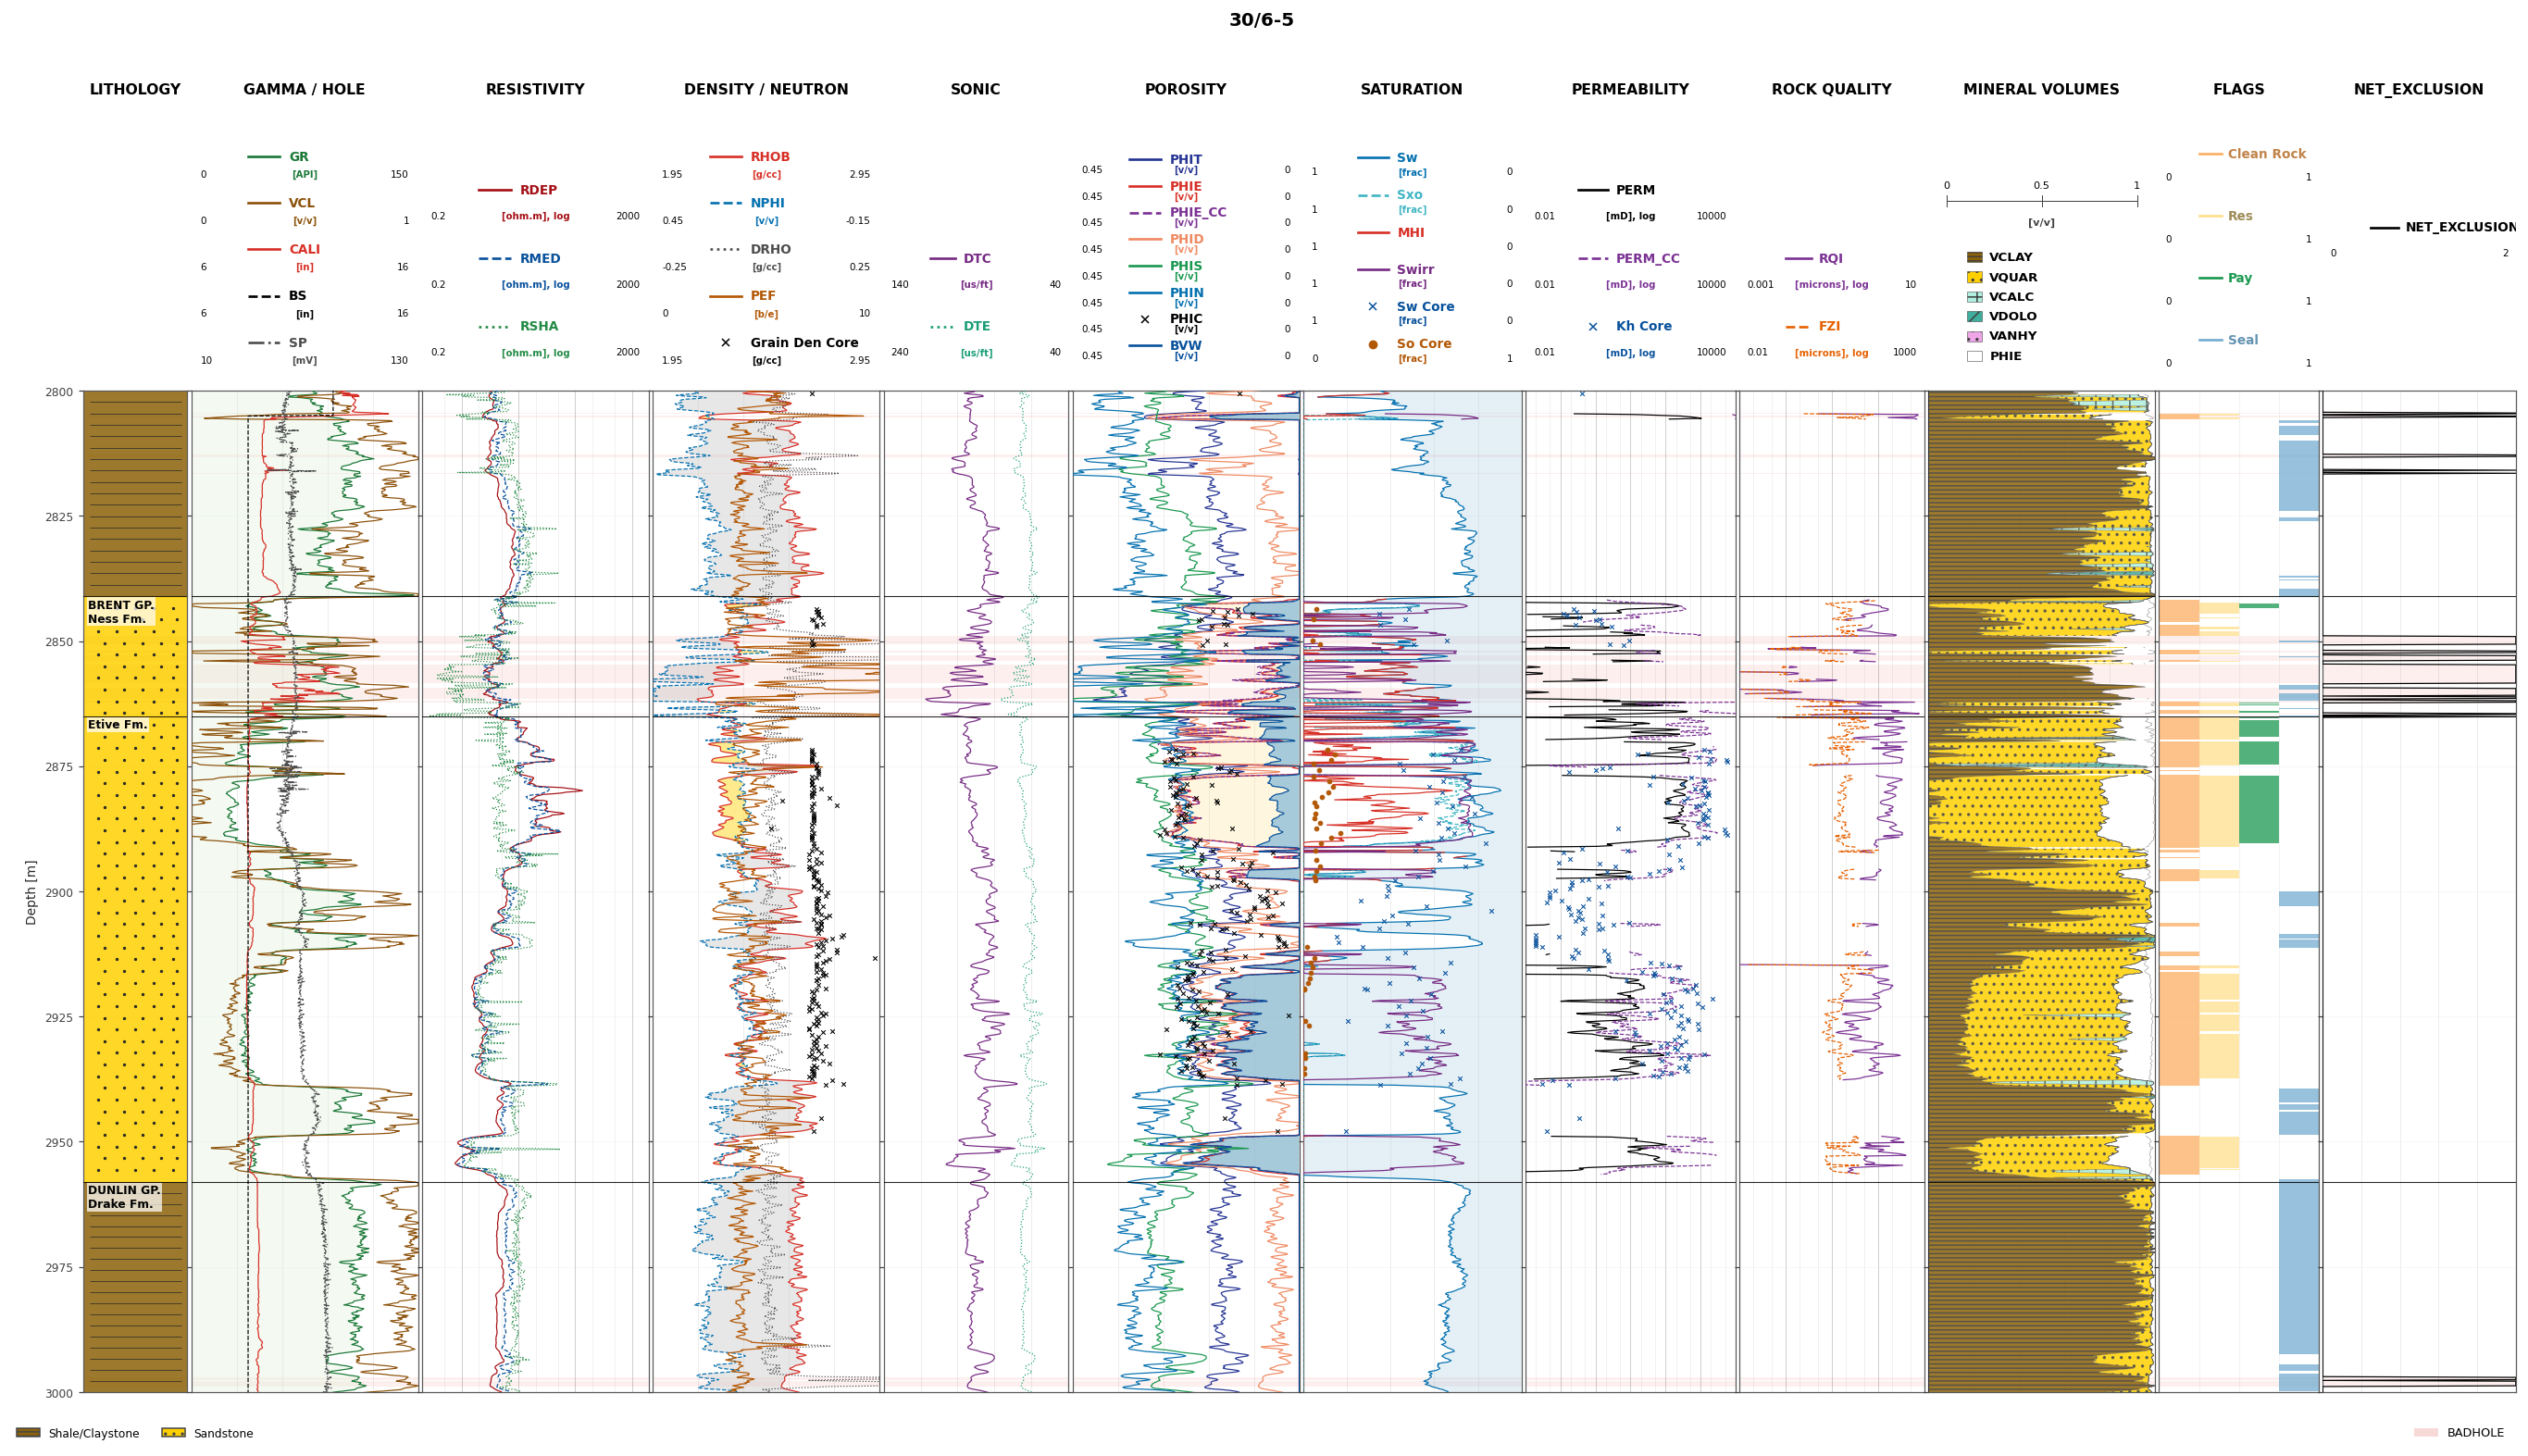

In [13]:
plot = await call("plot_well", target_id=run["interpretation_id"], top=2800, bottom=3000, dpi=110)
Image(data=b64decode(plot.content[0].data))

## 9 - Export

`export_results` writes inside the allowed folders; a relative path starts at the first
root (here the notebook's working folder), and an existing file is overwritten.

In [14]:
(await call("export_results", interpretation_id=run["interpretation_id"], path="exports/30_6-5.las")).structured_content

{'path': 'exports/30_6-5.las',
 'folder': 'petrophys-tutorial-wgfptn1m',
 'format': 'las',
 'bytes': 14689424,
 'size': '14.0 MB',
 'curves': 63}

## 10 - Connect a real client

Install the extra, check it, and let `petrophys-mcp config` print the exact setup for your
client (Claude Code, Claude Desktop, Cursor, VS Code or Codex):

```bash
pip install "petrophys[mcp]"
petrophys-mcp check --root /path/to/wells
petrophys-mcp config claude-code --root /path/to/wells
```

For a model that is not on your machine - a team server, a container, or a hosted model
such as OpenAI's - serve over HTTP with a token (`docker compose up` does the same in a
container):

```bash
petrophys-mcp serve --http --root /path/to/wells --token auto
petrophys-mcp config openai --url https://<your-host>/mcp --token <TOKEN>
```

`examples/mcp_openai_agent.py` connects an OpenAI model to a local server without a
public URL. The [LLM agents (MCP) guide](https://petrophys.netlify.app/mcp) covers every
option.

The server interprets with the library's default calculation profile, `"current"`. An
evaluation harness that must reproduce the GeoLink eval context package can pin that
package's calculations for every interpretation whose settings do not choose a profile,
with `petrophys-mcp serve --calculation-profile geolink` or the
`PETROPHYS_CALCULATION_PROFILE` environment variable, which only the MCP server reads;
`petrophys-mcp check` prints the profile in use.

Then ask, for example: *"Load my_well.las, interpret it with Rw = 0.05 ohm.m at 75 degF,
and tell me the net pay in each formation - list any warnings."*

## Pitfalls

- **Rw needs its temperature.** Pass `rw` together with `rw_meas_temp_f` in `settings`;
  without it the library takes Rw at the median formation temperature. Tell the model both values, or let it ask.
- **Mixed group/formation tops overlap.** Summaries of different levels are not
  additive; `summarize_zones` keeps one level (`rank="formation"` or `rank="group"`).
- **Whole-well totals can include the overburden.** Ask for the reservoir window
  (`summary_top`/`summary_bottom`, or `summarize_zones` with `top`/`bottom`).
- **File access is sandboxed.** Paths outside the `--root` folders are refused, and
  exports land inside them.

## Key takeaways

- The MCP server gives a model the Petrophys workflow, not a copy of it: results,
  traces and warnings are the ones `pp.interpret` produces.
- Settings are validated and errors are actionable, so a model can correct itself.
- File access is limited to the folders passed with `--root`.

## Try it yourself

> **Exercise 1.** Call `curve_statistics` with `target_id=run["interpretation_id"]`,
> `curves=["PHIE", "SW", "VCL"]` and the Brent Group window. Do the medians agree with
> `run["key_results"]`?
>
> **Exercise 2.** Run `interpret_well` again with `settings={"rw": 0.07}` only, then use
> `explain_step` on the new run's `rw` step. Which temperature was assumed, and how does
> the Brent Group average Sw from `summarize_zones` change?

## What's next

Next, **21_custom_workflows.ipynb** turns your interpretation into a reusable, shareable workflow. Apply the course end to end in the case studies (for example
`cs1_full_formation_evaluation_30_6-5.ipynb`), or bring your own well with the
[Your own data](../../docs/own_data.md) page.